In [4]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
%pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 1.3 MB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 1.4 MB/s eta 0:00:01
   ---------------------------- ----------- 1.3/1.8 MB 1.6 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 1.6 MB/s  0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1
Note: you may need to restart the kernel to use updated packages.


In [9]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
sns.set_theme(style="whitegrid")
orders = pd.DataFrame({
"order_id": range(101, 113),
"city": ["Lagos","Abuja","Lagos","Kano","Abuja","Lagos",
"Kano","Abuja","Lagos","Kano","Abuja","Lagos"],
"channel": ["Online","Store","Online","Store","Online","Store",
"Online","Online","Store","Store","Online","Online"],
"order_value": [2000,4000,3000,3500,5000,4500,
2500,3000,80000,4000,5500,3500],
"delivery_days": [2,4,3,5,2,3,6,2,4,5,3,2],
"age": [25,34,29,41,None,31,28,35,52,46,33,27]
})
assert orders["order_id"].is_unique
print(orders.shape) # (12, 6)
print(orders.head())
print(orders.dtypes)

(12, 6)
   order_id   city channel  order_value  delivery_days   age
0       101  Lagos  Online         2000              2  25.0
1       102  Abuja   Store         4000              4  34.0
2       103  Lagos  Online         3000              3  29.0
3       104   Kano   Store         3500              5  41.0
4       105  Abuja  Online         5000              2   NaN
order_id           int64
city                 str
channel              str
order_value        int64
delivery_days      int64
age              float64
dtype: object


In [12]:
print(orders.info())

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       12 non-null     int64  
 1   city           12 non-null     str    
 2   channel        12 non-null     str    
 3   order_value    12 non-null     int64  
 4   delivery_days  12 non-null     int64  
 5   age            11 non-null     float64
dtypes: float64(1), int64(3), str(2)
memory usage: 708.0 bytes
None


In [13]:
print(orders.isna().sum())

order_id         0
city             0
channel          0
order_value      0
delivery_days    0
age              1
dtype: int64


In [14]:
print(orders.nunique(dropna=False))

order_id         12
city              3
channel           2
order_value       9
delivery_days     5
age              12
dtype: int64


In [15]:
print(orders.duplicated(subset=["order_id"]).sum())

0


In [16]:
print(orders["city"].value_counts(dropna=False))

city
Lagos    5
Abuja    4
Kano     3
Name: count, dtype: int64


In [17]:
print(orders["age"].count()) # 11 non-null

11


In [18]:
print(orders["age"].isna().sum()) # 1 missing

1


In [19]:
print(orders["city"].mode())

0    Lagos
Name: city, dtype: str


In [20]:
print(orders["city"].value_counts(dropna=False))

city
Lagos    5
Abuja    4
Kano     3
Name: count, dtype: int64


In [21]:
print(orders["channel"].value_counts(normalize=True).mul(100))

channel
Online    58.333333
Store     41.666667
Name: proportion, dtype: float64


In [22]:
x = orders["order_value"]

In [23]:
print(x.mean()) # 10000.0

10041.666666666666


In [24]:
print(x.median()) # 3750.0

3750.0


In [25]:
print(x.mode()) # 3000, 3500, 4000 (multimodal)

0    3000
1    3500
2    4000
Name: order_value, dtype: int64


In [26]:
print(x.std()) # sample standard deviation

22054.12591097116


In [27]:
print(x.quantile([.25,.5,.75,.95]))

0.25     3000.0
0.50     3750.0
0.75     4625.0
0.95    39025.0
Name: order_value, dtype: float64


In [28]:
print(x.describe())

count       12.000000
mean     10041.666667
std      22054.125911
min       2000.000000
25%       3000.000000
50%       3750.000000
75%       4625.000000
max      80000.000000
Name: order_value, dtype: float64


In [29]:
summary = orders.groupby("city", as_index=False).agg(
orders=("order_id","nunique"),
total_revenue=("order_value","sum"),
mean_order=("order_value","mean"),
median_order=("order_value","median")
)

In [30]:
print(summary.sort_values("total_revenue", ascending=False))

    city  orders  total_revenue    mean_order  median_order
2  Lagos       5          93000  18600.000000        3500.0
0  Abuja       4          17500   4375.000000        4500.0
1   Kano       3          10000   3333.333333        3500.0


In [31]:
print(orders.groupby("channel")["order_value"].describe())

         count     mean           std     min     25%     50%     75%      max
channel                                                                       
Online     7.0   3500.0   1290.994449  2000.0  2750.0  3000.0  4250.0   5500.0
Store      5.0  19200.0  33990.072080  3500.0  4000.0  4000.0  4500.0  80000.0


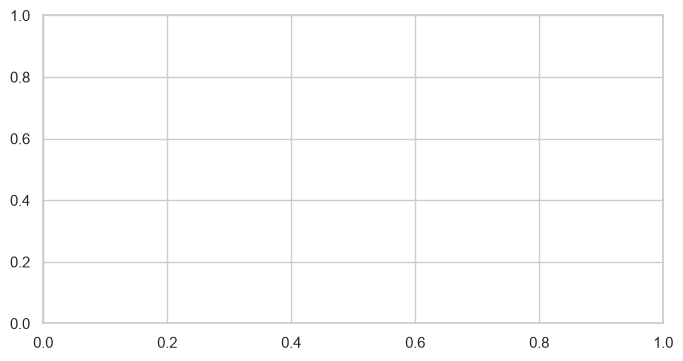

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))

In [33]:
sns.histplot(data=orders, x="order_value", bins=8, ax=ax)

<Axes: xlabel='order_value', ylabel='Count'>

In [34]:
ax.set(title="Order value distribution — fictional retail orders",
xlabel="Order value (NGN)", ylabel="Number of orders")

[Text(0.5, 1.0, 'Order value distribution — fictional retail orders'),
 Text(0.5, 4.444444444444445, 'Order value (NGN)'),
 Text(4.4444444444444375, 0.5, 'Number of orders')]

In [35]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [36]:
plt.show()

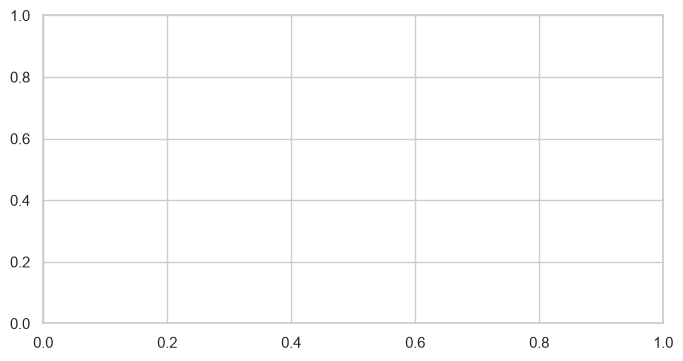

In [37]:
fig, ax = plt.subplots(figsize=(8,4))

In [38]:
sns.histplot(data=orders, x="order_value", bins=[0,2000,4000,6000,10000,100000],
ax=ax)

<Axes: xlabel='order_value', ylabel='Count'>

In [39]:
ax.set(xlabel="Order value (NGN)", ylabel="Orders",
title="Order values with business-defined bins")

[Text(0.5, 4.444444444444445, 'Order value (NGN)'),
 Text(4.4444444444444375, 0.5, 'Orders'),
 Text(0.5, 1.0, 'Order values with business-defined bins')]

In [40]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

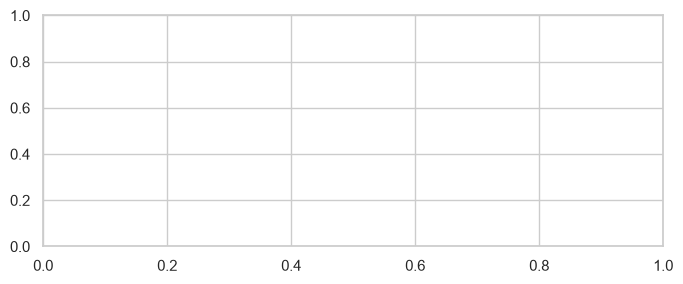

In [41]:
fig, ax = plt.subplots(figsize=(8,3))

In [42]:
sns.boxplot(data=orders, x="order_value", ax=ax)

<Axes: xlabel='order_value'>

In [43]:
ax.set(title="Order value spread and potential outliers",
xlabel="Order value (NGN)")

[Text(0.5, 1.0, 'Order value spread and potential outliers'),
 Text(0.5, 4.444444444444445, 'Order value (NGN)')]

In [44]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

In [46]:
q1, q3 = orders["order_value"].quantile([.25,.75])

In [48]:
iqr = q3 - q1

In [51]:
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr

In [54]:
flagged = orders.loc

In [60]:
[
(orders["order_value"] < lower) |
(orders["order_value"] > upper)
]

[0     False
 1     False
 2     False
 3     False
 4     False
 5     False
 6     False
 7     False
 8      True
 9     False
 10    False
 11    False
 Name: order_value, dtype: bool]

In [61]:
print(q1, q3, lower, upper)

3000.0 4625.0 562.5 7062.5


In [68]:
print(flagged[["order_id","order_value"]])

KeyError: "None of [Index(['order_id', 'order_value'], dtype='str')] are in the [index]"

In [69]:
print("Mean all:", orders["order_value"].mean())

Mean all: 10041.666666666666


In [73]:
print("Mean without flagged:",
orders.loc

_IncompleteInputError: incomplete input (3054669022.py, line 2)

In [74]:
print("Mean without flagged:",
orders.loc[~orders.index.isin(flagged.index),"order_value"].

_IncompleteInputError: incomplete input (4073026830.py, line 2)

In [75]:
print("Median all:", orders["order_value"].median())

Median all: 3750.0


In [76]:
counts = orders["city"].value_counts().rename_axis("city").reset_index(name="orders")

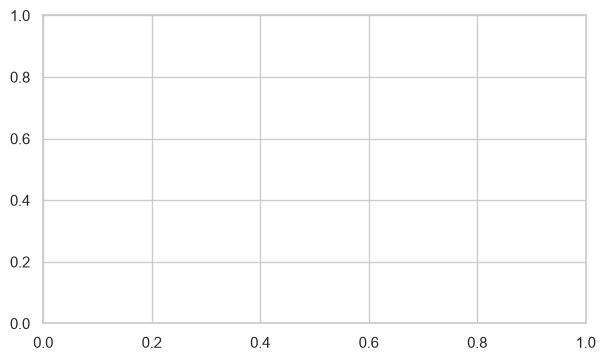

In [77]:
fig, ax = plt.subplots(figsize=(7,4))

In [78]:
sns.barplot(data=counts, x="city", y="orders", ax=ax)

<Axes: xlabel='city', ylabel='orders'>

In [79]:
ax.set(title="Order count by city", xlabel="City", ylabel="Number of orders")

[Text(0.5, 1.0, 'Order count by city'),
 Text(0.5, 4.444444444444445, 'City'),
 Text(4.4444444444444375, 0.5, 'Number of orders')]

In [80]:
ax.set_ylim(bottom=0)

(0.0, 5.25)

In [81]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

In [82]:
revenue = orders.groupby("city", as_index=False)["order_value"].sum()

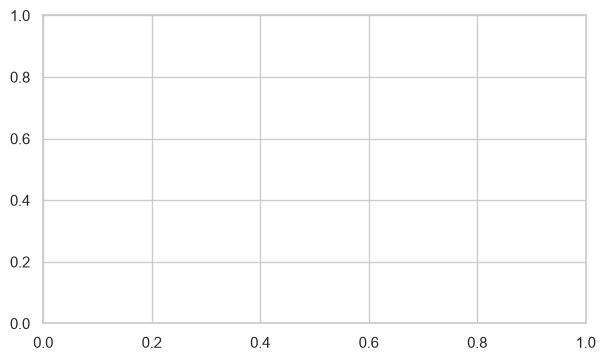

In [83]:
fig, ax = plt.subplots(figsize=(7,4))

In [84]:
sns.barplot(data=revenue, x="city", y="order_value", ax=ax)

<Axes: xlabel='city', ylabel='order_value'>

In [85]:
ax.set(title="Total revenue by city", xlabel="City", ylabel="Revenue (NGN)")

[Text(0.5, 1.0, 'Total revenue by city'),
 Text(0.5, 4.444444444444445, 'City'),
 Text(4.4444444444444375, 0.5, 'Revenue (NGN)')]

In [86]:
ax.set_ylim(bottom=0)

(0.0, 97650.0)

In [87]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

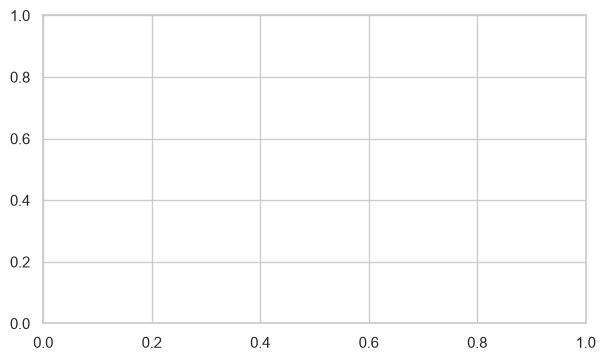

In [88]:
fig, ax = plt.subplots(figsize=(7,4))

In [89]:
sns.scatterplot(data=orders, x="delivery_days", y="order_value",
hue="channel", s=85, ax=ax)

<Axes: xlabel='delivery_days', ylabel='order_value'>

In [90]:
ax.set(title="Delivery time versus order value",
xlabel="Delivery time (days)", ylabel="Order value (NGN)")

[Text(0.5, 1.0, 'Delivery time versus order value'),
 Text(0.5, 4.444444444444445, 'Delivery time (days)'),
 Text(4.4444444444444375, 0.5, 'Order value (NGN)')]

In [91]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

In [92]:
print(orders[["delivery_days","order_value"]].corr(method="pearson"))

               delivery_days  order_value
delivery_days       1.000000     0.127917
order_value         0.127917     1.000000


In [93]:
print(orders[["delivery_days","order_value"]].corr(method="spearman"))

               delivery_days  order_value
delivery_days       1.000000     0.074162
order_value         0.074162     1.000000


In [94]:
numeric = orders[["order_value","delivery_days","age"]]

In [95]:
corr = numeric.corr(numeric_only=True)

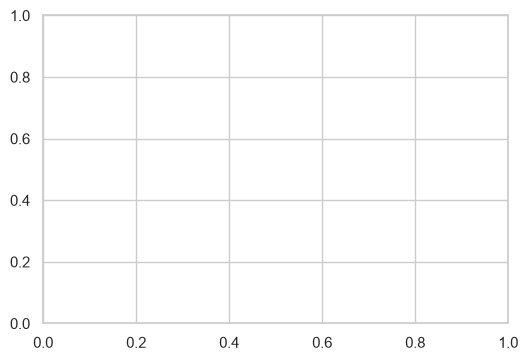

In [96]:
fig, ax = plt.subplots(figsize=(6,4))

In [97]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
vmin=-1, vmax=1, center=0, ax=ax)

<Axes: >

In [98]:
ax.set(title="Correlation among numeric variables")

[Text(0.5, 1.0, 'Correlation among numeric variables')]

In [99]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

In [100]:
cross = pd.crosstab(orders["city"], orders["channel"])

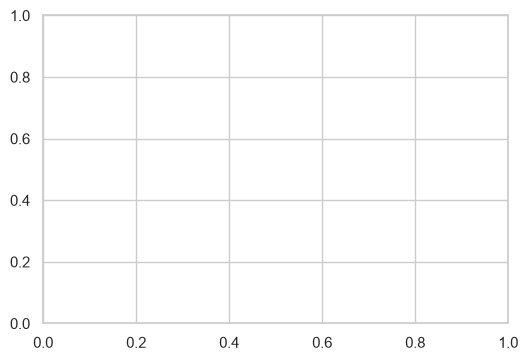

In [101]:
fig, ax = plt.subplots(figsize=(6,4))

In [102]:
sns.heatmap(cross, annot=True, fmt="d", cmap="Blues", ax=ax)

<Axes: xlabel='channel', ylabel='city'>

In [103]:
ax.set(title="Order counts: city by channel",
xlabel="Sales channel", ylabel="City")

[Text(0.5, 1.0, 'Order counts: city by channel'),
 Text(0.5, 4.444444444444445, 'Sales channel'),
 Text(4.444444444444445, 0.5, 'City')]

In [104]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

In [105]:
pct = pd.crosstab(orders["city"], orders["channel"],
normalize="index").mul(100)

In [106]:
print(pct.round(1))

channel  Online  Store
city                  
Abuja      75.0   25.0
Kano       33.3   66.7
Lagos      60.0   40.0


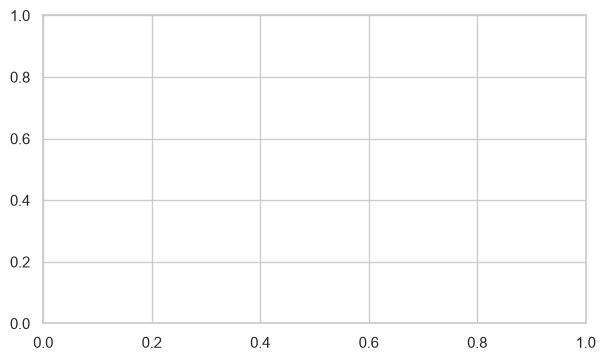

In [107]:
fig, ax = plt.subplots(figsize=(7,4))

In [108]:
sns.boxplot(data=orders, x="city", y="order_value", ax=ax)

<Axes: xlabel='city', ylabel='order_value'>

In [109]:
ax.set(title="Order value distribution by city",
xlabel="City", ylabel="Order value (NGN)")

[Text(0.5, 1.0, 'Order value distribution by city'),
 Text(0.5, 4.444444444444445, 'City'),
 Text(4.4444444444444375, 0.5, 'Order value (NGN)')]

In [110]:
plt.tight_layout(); plt.show()

<Figure size 640x480 with 0 Axes>

In [111]:
city_summary = orders.groupby("city")["order_value"].agg(
["count","mean","median","std"])

In [112]:
print(city_summary)

       count          mean  median           std
city                                            
Abuja      4   4375.000000  4500.0   1108.677891
Kano       3   3333.333333  3500.0    763.762616
Lagos      5  18600.000000  3500.0  34335.477279
